# Exercise 4: Feature Engineering & Feature Extraction
**Team:** Swiss Quant Industrial

This notebook creates an interpretable engineered feature from the Exercise 3 master table and parsed logbook. It answers Urs' concern directly: can the data capture something like the machine “rhythm” he feels on the shop floor?

The notebook uses semantic labels throughout: `0 = BAD`, `1 = GOOD`.


In [1]:
from pathlib import Path
import re
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 180)

BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR_150825 = BASE_DIR / "data" / "DataDump_150825"
DATA_DIR_300825 = BASE_DIR / "data" / "DataDump_300825"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}
RAW_TO_SEMANTIC_LABEL = {0: GOOD_CLASS, 1: BAD_CLASS}
BAD_SHIPPED_COST_CHF = 500
GOOD_WASTED_COST_CHF = 10

def feature_columns(df):
    return sorted([c for c in df.columns if c.startswith("feature_")], key=lambda c: int(c.split("_")[1]))

def standardize_manual_label(df, label_col="Manual_Label", raw_label_col="Manual_Label_Raw"):
    out = df.copy()
    raw = pd.to_numeric(out[label_col], errors="coerce")
    out[raw_label_col] = raw
    out[label_col] = raw.map(RAW_TO_SEMANTIC_LABEL).astype("Int64")
    return out

def add_label_name(df, label_col="Manual_Label"):
    out = df.copy()
    out[f"{label_col}_Name"] = out[label_col].map(LABEL_NAMES)
    return out

def load_master_table():
    df = pd.read_csv(OUTPUT_DIR / "exercise3_master_table_case_level.csv")
    if "Manual_Label" in df.columns:
        df["Manual_Label"] = pd.to_numeric(df["Manual_Label"], errors="coerce").astype("Int64")
    return df

def load_logbook_events():
    return pd.read_csv(OUTPUT_DIR / "logbook_events_structured.csv")

def load_heatwave_table():
    sensor = pd.read_csv(DATA_DIR_300825 / "sensor_data_august_shift.csv")
    quality = pd.read_csv(DATA_DIR_300825 / "quality_labels_august_shift.csv")
    production = pd.read_csv(DATA_DIR_300825 / "production_log_august_shift.csv", parse_dates=["Timestamp"])
    if len(sensor) != len(production):
        raise ValueError("Heatwave sensor and production logs should be row-aligned and equal length.")
    if not sensor["Charge_ID"].reset_index(drop=True).eq(production["Charge_ID"].reset_index(drop=True)).all():
        raise ValueError("Heatwave production rows are not row-aligned with sensor Charge_ID values.")
    table = sensor.merge(quality[["Case_ID", "Manual_Label", "Hash_Validation", "Legacy_Quality_Score"]], on="Case_ID", how="inner")
    if len(table) != len(sensor):
        raise ValueError("Heatwave quality merge changed row count; expected one label per Case_ID.")
    table = pd.concat([table.reset_index(drop=True), production.reset_index(drop=True)[["Timestamp", "Operator_ID"]]], axis=1)
    table = standardize_manual_label(table)
    table["label_available"] = table["Manual_Label"].notna()
    ts = pd.to_datetime(table["Timestamp"], errors="coerce")
    table["production_date"] = ts.dt.date
    table["production_hour"] = ts.dt.hour + ts.dt.minute / 60
    return add_label_name(table)

def _present_columns(df, cols):
    return [c for c in cols if c in df.columns]

def add_urs_rhythm_features(df, reference_df=None, source_features=("feature_2", "feature_4", "feature_5"), window=25):
    out = df.copy()
    signals = _present_columns(out, source_features)
    if not signals:
        raise ValueError("None of the rhythm source features are present.")
    reference = reference_df if reference_df is not None else out
    ref_numeric = reference[signals].apply(pd.to_numeric, errors="coerce")
    medians = ref_numeric.median()
    scales = ref_numeric.std().replace(0, np.nan).fillna(1.0)
    numeric = out[signals].apply(pd.to_numeric, errors="coerce").fillna(medians)
    standardized = (numeric - medians) / scales
    sort_cols = _present_columns(out, ["Timestamp_fixed", "Timestamp", "Charge_ID", "Case_ID"])
    ordered_index = out.sort_values(sort_cols).index if sort_cols else out.index
    ordered = standardized.loc[ordered_index]
    local_change = ordered.diff().abs().mean(axis=1).fillna(0.0)
    rolling_volatility = ordered.rolling(window=window, min_periods=3).std().mean(axis=1).fillna(0.0)
    rhythm = 0.4 * local_change + 0.6 * rolling_volatility
    out["Urs_Local_Signal_Change"] = local_change.reindex(out.index).astype(float)
    out["Urs_Rolling_Signal_Volatility"] = rolling_volatility.reindex(out.index).astype(float)
    out["Urs_Rhythm_Index"] = rhythm.reindex(out.index).astype(float)
    return out

def confusion_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "bad_correct": int(cm[0, 0]),
        "bad_shipped": int(cm[0, 1]),
        "good_wasted": int(cm[1, 0]),
        "good_correct": int(cm[1, 1]),
    }

def production_cost_chf(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    return counts["bad_shipped"] * BAD_SHIPPED_COST_CHF + counts["good_wasted"] * GOOD_WASTED_COST_CHF

def classification_summary(y_true, y_pred, model, threshold=None):
    counts = confusion_counts(y_true, y_pred)
    return {
        "model": model,
        "threshold": threshold,
        "rows": len(y_true),
        **counts,
        "bad_shipped_cost_chf": counts["bad_shipped"] * BAD_SHIPPED_COST_CHF,
        "good_wasted_cost_chf": counts["good_wasted"] * GOOD_WASTED_COST_CHF,
        "cost_chf": production_cost_chf(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
    }

def confusion_frame(y_true, y_pred):
    return pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )

def predict_from_bad_probability(prob_bad, threshold):
    return pd.Series(np.where(np.asarray(prob_bad) >= threshold, BAD_CLASS, GOOD_CLASS))


## 1. Feature Extraction vs. Feature Engineering

**Feature extraction** is algorithmic compression. A method such as PCA could reduce all 33 SORTEX columns into a few mathematical components. This may help a model, but it would be hard for Urs to trust because “principal component 1” is not a shop-floor concept.

**Feature engineering** is a domain-driven transformation. Urs talks about belt slip, vibration, surging, moisture, and rhythm. A volatility feature built from real production-order signals is easier to explain: it does not replace Urs' experience; it turns that experience into a measurable sensor signal.

For acceptance, the engineered feature is the better choice. It gives Urs a way to inspect whether the AI is noticing the same instability he notices physically.


In [2]:
master = load_master_table()
log_events = load_logbook_events()
labeled = master.dropna(subset=["Manual_Label"]).copy()
labeled["Manual_Label"] = labeled["Manual_Label"].astype(int)

log_evidence = log_events.loc[
    log_events["body"].str.contains("vibration|shak|belt speed|slip|surging|frequency|dampener|yield|reject|humidity|condensation", case=False, na=False),
    ["timestamp", "actor", "event", "issue_tags", "body"],
].head(16)

display(Markdown(f"Loaded **{len(master):,}** master rows and **{len(labeled):,}** labeled cases from Exercise 3."))
display(log_evidence)


Loaded **2,006** master rows and **1,404** labeled cases from Exercise 3.

,timestamp,actor,event,issue_tags,body
9,2025-07-28 06:35:00,4031,MANUAL_LOG,['belt_or_vibration'],Belt speed set to 1.5 m/s. Everything sounds n...
10,2025-07-28 07:05:00,4786,MANUAL_LOG,['yield_rejects'],"Line 3 is running, but the yield monitor is fl..."
11,2025-07-28 07:15:00,1691,MANUAL_LOG,"['yield_rejects', 'belt_or_vibration']","4786, I'm watching the belt from the catwalk. ..."
14,2025-07-28 07:55:00,4786,MANUAL_LOG,"['yield_rejects', 'belt_or_vibration', 'sensor...",Recalibration didn't work. The SORTEX is still...
15,2025-07-28 08:15:00,3898,QC_LOG,['yield_rejects'],We are wasting prime material here. I just che...
16,2025-07-28 08:40:00,4031,MANUAL_LOG,['yield_rejects'],"The reject bin is already 80% full. Usually, t..."
21,2025-07-28 10:30:00,7290,MANUAL_LOG,"['yield_rejects', 'maintenance']","Don't worry about the machine, kids. Machines ..."
22,2025-07-28 11:15:00,4786,MANUAL_LOG,"['yield_rejects', 'maintenance']",Yield is still terrible. Left side rejecting n...
25,2025-07-28 12:45:00,1691,MANUAL_LOG,['yield_rejects'],We have 6 full bins of mixed rejects now. We n...
27,2025-07-28 14:00:00,4786,SHIFT_HANDOVER,"['yield_rejects', 'maintenance']",Handing over to afternoon shift. Line 3 is lim...


## 2. Engineer `Urs_Rhythm_Index`

The feature is computed from `feature_2`, `feature_4`, and `feature_5`, the real sorter signals that show strong process relevance in Exercise 3 and are available again in the heatwave data. The calculation orders cases by repaired production time and combines two ideas:

- **Local signal change:** abrupt jumps from one case to the next.
- **Rolling signal volatility:** instability over the recent case stream.

A higher `Urs_Rhythm_Index` means the sensor stream is less stable. This is the measurable analogue of Urs' “the floor shakes / the belt is slipping / the rhythm changed” language.


In [3]:
engineered_all = add_urs_rhythm_features(master)
engineered = engineered_all.dropna(subset=["Manual_Label"]).copy()
engineered["Manual_Label"] = engineered["Manual_Label"].astype(int)
engineered["Manual_Label_Name"] = engineered["Manual_Label"].map(LABEL_NAMES)

export_cols = ["Case_ID", "Charge_ID", "Timestamp_fixed", "Manual_Label", "Manual_Label_Name", "feature_2", "feature_4", "feature_5", "Urs_Local_Signal_Change", "Urs_Rolling_Signal_Volatility", "Urs_Rhythm_Index"]
export_cols = [c for c in export_cols if c in engineered.columns]
export_path = OUTPUT_DIR / "exercise4_engineered_features.csv"
engineered[export_cols].to_csv(export_path, index=False)

display(Markdown(f"Saved engineered feature table to `{export_path.relative_to(BASE_DIR)}`."))
display(engineered[export_cols].head())


Saved engineered feature table to `outputs/exercise4_engineered_features.csv`.

,Case_ID,Charge_ID,Timestamp_fixed,Manual_Label,Manual_Label_Name,feature_2,feature_4,feature_5,Urs_Local_Signal_Change,Urs_Rolling_Signal_Volatility,Urs_Rhythm_Index
1,32,0,2025-08-11 11:31:30,1,GOOD,778.0,105,21,0.794576,1.144922,1.004783
2,52,0,2025-08-11 11:31:30,1,GOOD,NaN,210,33,0.982644,1.146720,1.081089
7,144,0,2025-08-11 11:31:30,1,GOOD,NaN,150,23,0.567519,0.879209,0.754533
8,156,0,2025-08-11 11:31:30,1,GOOD,1260.0,164,26,0.692394,0.879364,0.804576
13,231,0,2025-08-11 11:31:30,1,GOOD,1042.0,163,30,0.576306,0.633214,0.610451


## 3. Does the Feature Help Explain Quality?

The feature is not presented as a stand-alone classifier. Its value is that it captures process instability in a way that can be inspected by operators and reused by the unrestricted model. The summary table compares BAD and GOOD cases; the figures show whether high-rhythm periods cluster with quality risk.


,Manual_Label_Name,cases,rhythm_mean,rhythm_median,rhythm_p90,feature_2_mean,feature_4_mean,feature_5_mean
0,BAD,722,0.238963,0.123150,0.661279,300.527378,60.554017,14.853186
1,GOOD,682,0.824907,0.805352,1.311376,921.521318,160.851906,30.755132


,metric,corr_with_BAD_indicator
4,Urs_Rolling_Signal_Volatility,-0.629784
5,Urs_Rhythm_Index,-0.623079
1,feature_4,-0.620148
0,feature_2,-0.580872
2,feature_5,-0.548442
3,Urs_Local_Signal_Change,-0.495736


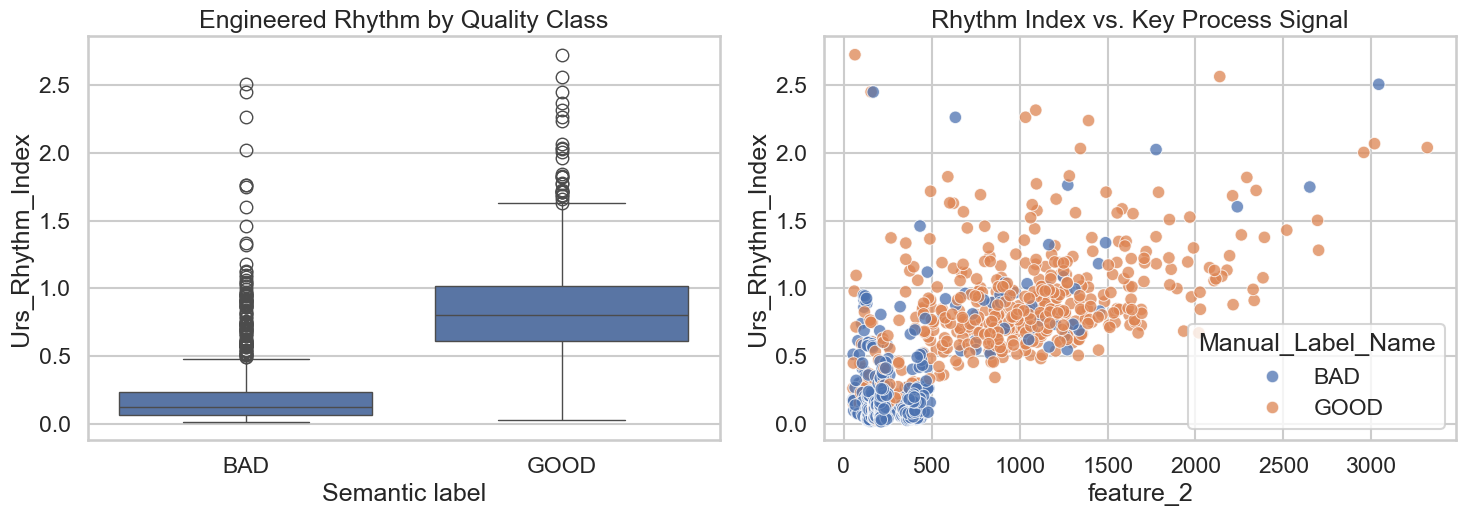

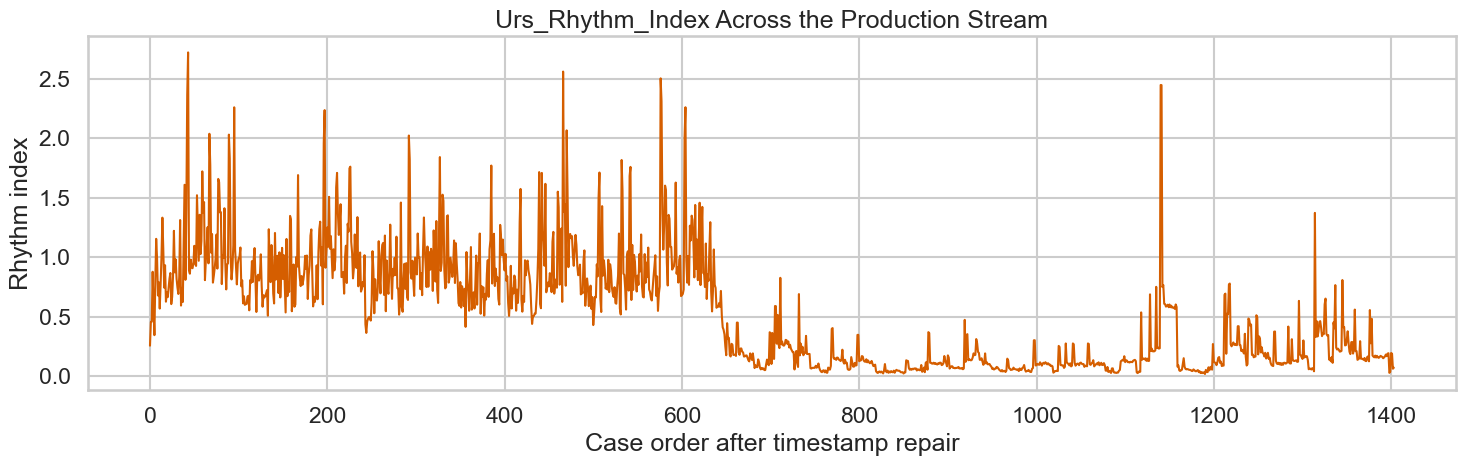

The engineered rhythm feature is lower for BAD cases (median 0.123) than for GOOD cases (median 0.805). For Urs, the point is not that the code literally smells the motor; it converts the same kind of short-run instability he listens for into a repeatable sensor-derived signal. For the business case, this makes the model easier to trust because the feature has an operational interpretation, not just a statistical name.

In [4]:
summary = engineered.groupby("Manual_Label_Name").agg(
    cases=("Case_ID", "count"),
    rhythm_mean=("Urs_Rhythm_Index", "mean"),
    rhythm_median=("Urs_Rhythm_Index", "median"),
    rhythm_p90=("Urs_Rhythm_Index", lambda s: s.quantile(0.90)),
    feature_2_mean=("feature_2", "mean"),
    feature_4_mean=("feature_4", "mean"),
    feature_5_mean=("feature_5", "mean"),
).reset_index()

corr_table = pd.DataFrame([
    {"metric": col, "corr_with_BAD_indicator": engineered[col].corr(engineered["Manual_Label"].eq(BAD_CLASS).astype(float))}
    for col in ["feature_2", "feature_4", "feature_5", "Urs_Local_Signal_Change", "Urs_Rolling_Signal_Volatility", "Urs_Rhythm_Index"]
]).sort_values("corr_with_BAD_indicator", key=lambda s: s.abs(), ascending=False)

display(summary)
display(corr_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=engineered, x="Manual_Label_Name", y="Urs_Rhythm_Index", order=["BAD", "GOOD"], ax=axes[0])
axes[0].set_title("Engineered Rhythm by Quality Class")
axes[0].set_xlabel("Semantic label")
sns.scatterplot(data=engineered, x="feature_2", y="Urs_Rhythm_Index", hue="Manual_Label_Name", hue_order=["BAD", "GOOD"], alpha=0.75, ax=axes[1])
axes[1].set_title("Rhythm Index vs. Key Process Signal")
plt.tight_layout()
plt.show()

ordered = engineered.sort_values(["Timestamp_fixed", "Charge_ID", "Case_ID"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(ordered.index, ordered["Urs_Rhythm_Index"], color="#d55e00", linewidth=1.5)
ax.set_title("Urs_Rhythm_Index Across the Production Stream")
ax.set_xlabel("Case order after timestamp repair")
ax.set_ylabel("Rhythm index")
plt.tight_layout()
plt.show()


bad_rhythm = float(summary.loc[summary["Manual_Label_Name"].eq("BAD"), "rhythm_median"].iloc[0])
good_rhythm = float(summary.loc[summary["Manual_Label_Name"].eq("GOOD"), "rhythm_median"].iloc[0])
rhythm_caption = (
    f"The engineered rhythm feature is lower for BAD cases (median {bad_rhythm:.3f}) than for GOOD cases "
    f"(median {good_rhythm:.3f}). For Urs, the point is not that the code literally smells the motor; "
    "it converts the same kind of short-run instability he listens for into a repeatable sensor-derived signal. "
    "For the business case, this makes the model easier to trust because the feature has an operational interpretation, not just a statistical name."
)
display(Markdown(rhythm_caption))


## 4. Final Exercise 4 Answer

- **Technique implemented:** feature engineering, not feature extraction.
- **Why this technique fits the case:** it is physically interpretable and speaks Urs' language.
- **What the feature represents:** short-term volatility in key sorter signals over the repaired production sequence.
- **How it affects acceptance:** it reframes AI as an additional instrument for Urs rather than an opaque replacement for his experience.
- **Downstream use:** the feature is exported for Exercise 7 and recomputed for Exercise 9, so the modeling chain uses the same definition across time periods.
